# Modelo SARIMAX para pronosticar una semana, hora por hora

Se pronostican las 24 horas de cada uno de los próximos 7 días: 168 precios, de h = 3 a
h = 9, igual que en `4_modelo_xgboost.ipynb`. Son 24 modelos, uno por hora, cada uno con
su serie diaria de `lp` y ciclo semanal (s = 7):

$$\phi(B)\,\Phi(B^7)\,(1-B)^d(1-B^7)^D\,\big(lp_t - x_t'\beta\big) = \theta(B)\,\Theta(B^7)\,\varepsilon_t$$

Todo se decide con criterios estadísticos y con datos hasta 2022.

| Etapa | Qué hace | Datos |
|---|---|---|
| 0 | Arma la serie, el calendario y las exógenas | todo el panel |
| 1 | Comprueba el flujo y mide el tiempo | hasta 2022 |
| 2 | Órdenes: KPSS, OCSB y AICc | 2015-2019 |
| 3 | Exógenas: preblanqueo, AICc y prueba t | 2015-2019 |
| 4 | Walk-forward mensual de las versiones; congela la configuración | 2020-2022 |
| 5 | Test, una sola vez | 2023-2025 y 2026 |
| 6 | Semana final: del 9 al 15 de octubre de 2026 | hasta el 6 de octubre de 2026 |
| 7 | Comparación con XGBoost | lo guardado |

Cada etapa guarda en `resultados/modelo_sarimax/` y no se repite si el archivo ya existe.
La etapa 5 y la 7 solo corren con la variable de entorno `CORRER_TEST=1`, y la 6 con
`CORRER_FINAL=1`.

**Criterio, fijado antes de abrir el test.** En el bloque h = 3 a 9, el RMSE en log debe
bajar al menos 5% frente al mejor de los dos ingenuos, con Diebold-Mariano p < 0,05.
También se reportan h = 3, h = 3 a 7 y h = 8 a 9. El umbral es decisión del autor, el
mismo de XGBoost. Para SARIMAX este bloque sí queda fijado antes de ver su test.

**Resultado.** Las pruebas eligieron el modelo más simple: un solo orden, (1,1,2)(0,0,2) con
s = 7, sin exógenas. En h = 3 a 9 funciona con el criterio: mejora 6,4% en 2023-2025 y 5,6% en
2026. XGBoost sigue siendo mejor, con 11,6% y 10,0%, aunque la diferencia solo es significativa
en 2023-2025. Ninguno de los dos anticipa bien el nivel del día. El detalle está en
`resultados/modelo_sarimax/RESULTADOS.md`.

In [1]:
suppressPackageStartupMessages({
  library(forecast)
  library(data.table)
  library(parallel)
  library(jsonlite)
  library(ggplot2)
})
options(repr.plot.width = 10, repr.plot.height = 4.2, repr.plot.res = 150, digits = 4)
setDTthreads(4)

CORRER_TEST <- Sys.getenv("CORRER_TEST") == "1"
CORRER_FINAL <- Sys.getenv("CORRER_FINAL") == "1"

PANELES <- "paneles"
SALIDA <- "resultados/modelo_sarimax"
XGB <- "resultados/modelo_xgboost"
dir.create(SALIDA, recursive = TRUE, showWarnings = FALSE)

HORAS <- 1:24
HORIZONTES <- 3:9                     # la semana que de verdad se puede pronosticar
REZAGO <- max(HORIZONTES)             # con este rezago, x(t+h-9) ya se conoce en t
INICIO <- as.Date("2015-03-01")
FIN_ELECCION <- as.Date("2019-12-31")
FIN_REFERENCIA <- as.Date("2017-12-31")
FIN_VALIDACION <- as.Date("2022-12-31")
FIN_TEST <- as.Date("2025-12-31")
ORIGEN_FINAL <- as.Date("2026-10-06")
MESES_VALIDACION <- seq(as.Date("2020-01-01"), as.Date("2022-12-01"), by = "month")
MESES_TEST <- seq(as.Date("2023-01-01"), as.Date("2025-12-01"), by = "month")
MESES_2026 <- seq(as.Date("2026-01-01"), as.Date("2026-10-01"), by = "month")

# Las mismas reglas de limpieza de 2d_seleccion_variables.py
CASI_CONSTANTE <- 0.99
MAX_FUERA_DE_RANGO <- 0.25
SIGUEN_AL_DOLAR <- c("precio_cargo_conf", "trm")
MAX_EXOGENAS <- 6
NIVEL <- 0.05
MIN_HORAS <- 12                       # la mitad de las horas

# La fecha más lejana que se puede leer. Sube solo en las etapas 5 y 6.
TECHO <- FIN_VALIDACION
NUCLEOS <- 10

MEJORA_MINIMA <- 5
BLOQUES <- list("h = 3 a 9" = 3:9, "h = 3" = 3L, "h = 3 a 7" = 3:7, "h = 8 a 9" = 8:9)

# Colores: paleta categórica de la guía de gráficas del proyecto, tema claro
AZUL <- "#2a78d6"; NARANJA <- "#eb6834"; AGUA <- "#1baf7a"
FONDO <- "#fcfcfb"; TEXTO_2 <- "#52514e"; REJILLA <- "#e5e4df"

guardar <- function(d, ruta) {
  # Escribe aparte y renombra, para que un archivo a medias nunca cuente como etapa hecha
  tmp <- sub("(\\.csv(\\.gz)?)$", ".tmp\\1", ruta)
  fwrite(d, tmp)
  for (intento in 1:5) {                # OneDrive a veces bloquea el archivo un momento
    if (file.rename(tmp, ruta)) return(invisible(ruta))
    Sys.sleep(5 * intento)
  }
  stop("no se pudo guardar ", ruta)
}

## Etapa 0. Datos

`LP` tiene una fila por día y una columna por hora. Las candidatas son las variables base
de `panel_caracteristicas.csv.gz`, que ya traen aplicado su atraso de publicación: la fila
t solo tiene lo que se conoce al cierre de t.

Cada exógena entra con 9 días de rezago: en la fila del día d va el valor de la fila d − 9.
Así, al pronosticar desde t hasta t + 9, nunca se usa nada posterior a t. El calendario sí
es el del día objetivo, porque se conoce de antemano.

In [2]:
tabla <- fread(file.path(PANELES, "panel_horario_modelo.csv.gz"),
               select = c("fecha", "hora", "lp", "es_festivo", paste0("es_festivo_h", c(1:7, 14, 30))))
tabla[, fecha := as.Date(fecha)]
setorder(tabla, fecha, hora)
stopifnot(nrow(tabla) == uniqueN(tabla$fecha) * 24, min(tabla$fecha) == INICIO, max(tabla$fecha) == ORIGEN_FINAL)

FECHAS <- seq(INICIO, ORIGEN_FINAL + REZAGO, by = "day")
LP <- matrix(NA_real_, length(FECHAS), 24)
LP[seq_len(uniqueN(tabla$fecha)), ] <- matrix(tabla$lp, ncol = 24, byrow = TRUE)

# El calendario llega más allá del último día del panel: es_festivo_hk dice si t + k es festivo
dia <- tabla[hora == 1]
FEST <- rep(NA_real_, length(FECHAS))
FEST[match(dia$fecha, FECHAS)] <- dia$es_festivo
for (k in c(1:7, 14, 30)) {
  j <- match(dia$fecha + k, FECHAS)
  FEST[j[!is.na(j)]] <- dia[[paste0("es_festivo_h", k)]][!is.na(j)]
}
stopifnot(!anyNA(FEST))

info <- fread(file.path(PANELES, "panel_caracteristicas_variables.csv"))
nombres <- info[entra == TRUE & tipo %in% c("diaria", "horaria"), variable]
pc <- fread(file.path(PANELES, "panel_caracteristicas.csv.gz"), select = c("fecha", "hora", nombres))
pc[, fecha := as.Date(fecha)]
setorder(pc, fecha, hora)
stopifnot(nrow(pc) == uniqueN(pc$fecha) * 24)
filas <- match(FECHAS - REZAGO, unique(pc$fecha))
stopifnot(!anyNA(filas))
X <- setNames(lapply(nombres, function(v) {
  m <- matrix(as.numeric(pc[[v]]), ncol = 24, byrow = TRUE)
  for (H in HORAS) m[, H] <- nafill(m[, H], type = "locf")    # solo hacia atrás, nunca del futuro
  m[filas, ]
}), nombres)

n_eleccion <- match(FIN_ELECCION, FECHAS)
cat(sprintf("%d días, %s a %s (con calendario hasta %s)\n", sum(!is.na(LP[, 1])), min(tabla$fecha), max(tabla$fecha), max(FECHAS)))
cat(sprintf("%d variables base; %d días para elegir órdenes y exógenas\n", length(X), n_eleccion))

4238 días, 2015-03-01 a 2026-10-06 (con calendario hasta 2026-10-15)


133 variables base; 1767 días para elegir órdenes y exógenas


## Reglas comunes

- **Reentrenamiento.** Los coeficientes se estiman el 1 de cada mes con todo lo anterior.
  Dentro del mes solo se actualiza el estado del modelo con los datos nuevos, sin
  reestimar. Es el mismo calendario de XGBoost.
- **Sin purga.** XGBoost la necesita porque sus objetivos miran h días adelante. Aquí la
  estimación solo usa `lp` hasta el día anterior al corte, y ningún dato cae en el mes
  evaluado.
- **Un techo.** `indice()` falla si se pide algo posterior a `TECHO`, y por eso las etapas
  1 a 4 no pueden leer 2023.
- **Si un mes no converge,** se reutilizan los coeficientes del mes anterior y se cuenta.
- **El error.** Promedio por día del error cuadrático en log, con error estándar de
  Newey-West (15 rezagos: h − 1 + 7 con h = 9). Fuente: Newey y West (1987). Diebold-Mariano
  usa esa varianza. Fuente: Diebold y Mariano (1995).

In [3]:
indice <- function(fin) {
  if (fin > TECHO) stop("dato posterior a ", TECHO)
  seq_len(match(fin, FECHAS))
}

diseno <- function(i, H, vars) {
  m <- matrix(FEST[i], ncol = 1, dimnames = list(NULL, "festivo"))
  for (v in vars) m <- cbind(m, X[[v]][i, H])
  colnames(m) <- c("festivo", vars)
  m
}

ajustar <- function(H, fin, orden, vars = character(0)) {
  i <- indice(fin)
  y <- ts(LP[i, H], frequency = 7)
  xr <- diseno(i, H, vars)
  o <- as.integer(orden)
  est <- function(m) Arima(y, order = o[1:3], seasonal = list(order = o[4:6], period = 7), xreg = xr, method = m)
  tryCatch(est("CSS-ML"), error = function(e) est("ML"))
}

pronosticar <- function(fit, H, t, vars = character(0)) {
  i <- indice(t)
  n <- length(i)
  actual <- Arima(ts(LP[i, H], frequency = 7), model = fit, xreg = diseno(i, H, vars))
  f <- forecast(actual, xreg = diseno(n + seq_len(REZAGO), H, vars), h = REZAGO, level = 80)
  data.frame(fecha = FECHAS[n], hora = H, h = HORIZONTES, lp_hat = as.numeric(f$mean)[HORIZONTES],
             lo80 = as.numeric(f$lower)[HORIZONTES], hi80 = as.numeric(f$upper)[HORIZONTES])
}

una_hora <- function(H, plan, vars, cortes, fin, tope) {
  siguientes <- c(cortes[-1], fin + 1)
  salida <- list()
  previo <- NULL
  fallos <- 0L
  for (k in seq_along(cortes)) {
    origenes <- FECHAS[FECHAS >= cortes[k] & FECHAS < siguientes[k] & FECHAS + min(HORIZONTES) <= tope]
    if (!length(origenes)) next
    fit <- tryCatch(ajustar(H, cortes[k] - 1, plan[H, ], vars), error = function(e) NULL)
    if (is.null(fit)) {
      fallos <- fallos + 1L
      fit <- previo
    }
    previo <- fit
    for (j in seq_along(origenes)) salida[[length(salida) + 1]] <- pronosticar(fit, H, origenes[j], vars)
  }
  r <- do.call(rbind, salida)
  list(pred = r[r$fecha + r$h <= tope, ], fallos = fallos)
}

poner_x <- function(x) {
  assign("X", x, envir = globalenv())
  NULL
}

con_nucleos <- function(f, vars = character(0)) {
  cl <- makeCluster(NUCLEOS)
  on.exit(stopCluster(cl))
  clusterEvalQ(cl, suppressPackageStartupMessages(library(forecast)))
  clusterExport(cl, c("LP", "FEST", "FECHAS", "TECHO", "REZAGO", "HORIZONTES", "FIN_ELECCION", "ORIGEN_FINAL", "n_eleccion",
                      "indice", "diseno", "ajustar", "pronosticar", "una_hora",
                      "elegir_orden", "blanquear", "tarea_aicc", "pruebas_t", "ljung_box", "pronostico_final"), envir = globalenv())
  clusterCall(cl, poner_x, X[vars])
  f(cl)
}

correr <- function(ruta, plan, vars, cortes, fin, tope) {
  if (file.exists(ruta)) return(fread(ruta)[, fecha := as.Date(fecha)][])
  r <- con_nucleos(function(cl) parLapplyLB(cl, HORAS, una_hora, plan, vars, cortes, fin, tope, chunk.size = 1), vars)
  p <- rbindlist(lapply(r, `[[`, "pred"))
  setorder(p, fecha, hora, h)
  guardar(p, ruta)
  guardar(data.table(hora = HORAS, meses_sin_converger = sapply(r, `[[`, "fallos")), sub("\\.csv\\.gz$", "_fallos.csv", ruta))
  p[, fecha := as.Date(fecha)][]
}

completar <- function(p) {
  # Agrega el objetivo y el ingenuo semanal, con la misma fórmula de XGBoost
  stopifnot(max(p$fecha + p$h) <= TECHO)
  d <- copy(p)
  d[, i := match(fecha, FECHAS)]
  d[, lp_t := LP[cbind(i, hora)]]
  d[, y := LP[cbind(i + h, hora)] - lp_t]
  d[, y_hat := lp_hat - lp_t]
  d[, y_semanal := LP[cbind(i - (7L * ceiling(h / 7) - h), hora)] - lp_t]
  stopifnot(!anyNA(d$y), !anyNA(d$y_hat), !anyNA(d$y_semanal))
  d[]
}

rmse <- function(e) sqrt(mean(e ^ 2))

media_y_ee <- function(d, L) {
  # Promedio de una serie diaria y su error estándar de Newey-West con L rezagos
  n <- length(d)
  u <- d - mean(d)
  v <- mean(u * u)
  for (l in seq_len(min(L, n - 1))) v <- v + 2 * (1 - l / (L + 1)) * mean(u[(l + 1):n] * u[1:(n - l)])
  c(media = mean(d), ee = sqrt(v / n))
}

diebold_mariano <- function(e_a, e_b, fechas, L) {
  # Pérdida cuadrática promediada por día. t negativo: a es mejor que b.
  d <- as.numeric(tapply(e_a ^ 2 - e_b ^ 2, fechas, mean))
  m <- media_y_ee(d, L)
  t <- unname(m["media"] / m["ee"])
  c(t = t, p = 2 * pnorm(-abs(t)))
}

criterio <- function(d, bloques = BLOQUES) {
  rbindlist(lapply(names(bloques), function(n) {
    g <- d[h %in% bloques[[n]]]
    e <- g$y - g$y_hat
    e_dia <- g$y
    e_sem <- g$y - g$y_semanal
    usa_dia <- rmse(e_dia) <= rmse(e_sem)
    e_ing <- if (usa_dia) e_dia else e_sem
    mejora <- 100 * (1 - rmse(e) / rmse(e_ing))
    r <- diebold_mariano(e, e_ing, g$fecha, max(bloques[[n]]) - 1 + 7)
    data.table(bloque = n, rmse_log = rmse(e), mejor_ingenuo = if (usa_dia) "del día" else "semanal", rmse_ingenuo = rmse(e_ing),
               mejora = mejora, dm_t = r[["t"]], dm_p = r[["p"]], funciona = mejora >= MEJORA_MINIMA & r[["p"]] < NIVEL)
  }))
}

# Las tareas de cada etapa, que corren en los núcleos
elegir_orden <- function(H) {
  i <- seq_len(n_eleccion)
  m <- auto.arima(ts(LP[i, H], frequency = 7), xreg = diseno(i, H, character(0)), ic = "aicc",
                  test = "kpss", seasonal.test = "ocsb", max.d = 1, max.D = 1, max.p = 5, max.q = 5,
                  max.P = 2, max.Q = 2, allowdrift = FALSE, stepwise = TRUE, approximation = FALSE)
  a <- m$arma
  data.frame(hora = H, p = a[1], d = a[6], q = a[2], P = a[3], D = a[7], Q = a[4], aicc = m$aicc)
}

blanquear <- function(H, plan, vars) {
  # Fuente: Box y Jenkins, identificación de funciones de transferencia
  i <- seq_len(n_eleccion)
  o <- as.integer(plan[H, ])
  m0 <- Arima(ts(LP[i, H], frequency = 7), order = o[1:3], seasonal = list(order = o[4:6], period = 7), method = "CSS-ML")
  ry <- as.numeric(residuals(m0))
  fuera <- seq_len(max(1L, sum(o[c(1, 2)]) + 7L * sum(o[c(4, 5)])))
  sapply(vars, function(v) {
    rx <- tryCatch(as.numeric(residuals(Arima(ts(X[[v]][i, H], frequency = 7), model = m0))), error = function(e) NULL)
    if (is.null(rx) || sd(rx[-fuera]) == 0) return(0)
    cor(ry[-fuera], rx[-fuera])
  })
}

tarea_aicc <- function(t, plan) {
  tryCatch(ajustar(t$H, FIN_ELECCION, plan[t$H, ], t$vars)$aicc, error = function(e) NA_real_)
}

pruebas_t <- function(H, plan, vars) {
  f <- ajustar(H, FIN_ELECCION, plan[H, ], vars)
  b <- coef(f)[vars]
  se <- sqrt(diag(f$var.coef))[vars]
  2 * pnorm(-abs(b / se))
}

ljung_box <- function(H, plan, vars) {
  # Fuente: Ljung y Box (1978)
  f <- ajustar(H, FIN_ELECCION, plan[H, ], vars)
  Box.test(residuals(f), lag = 14, type = "Ljung-Box", fitdf = sum(plan[H, c("p", "q", "P", "Q")]))$p.value
}

pronostico_final <- function(H, plan, vars) {
  pronosticar(ajustar(H, ORIGEN_FINAL, plan[H, ], vars), H, ORIGEN_FINAL, vars)
}

## Etapa 1. Comprobar el flujo

- Alterar precios o exógenas posteriores al origen no puede cambiar el pronóstico.
- En la fila de t + 9, la exógena tiene que ser el valor de la fila t.
- Pedir un dato de 2023 tiene que fallar.
- Se mide cuánto tarda cada paso, para corregir la estimación.

In [4]:
H <- 19
orden_prueba <- c(p = 2, d = 1, q = 1, P = 0, D = 1, Q = 1)
vc <- names(X)[c(1, 50)]

t0 <- Sys.time()
fit <- ajustar(H, FIN_VALIDACION, orden_prueba, vc)
s_ajuste <- as.numeric(difftime(Sys.time(), t0, units = "secs"))
t0 <- Sys.time()
for (k in 1:5) invisible(pronosticar(fit, H, FIN_VALIDACION - 20 - k, vc))
s_actualiza <- as.numeric(difftime(Sys.time(), t0, units = "secs")) / 5
cat(sprintf("un ajuste: %.1f s | una actualización con pronóstico: %.2f s\n", s_ajuste, s_actualiza))
n_ajustes <- 24 * (2 * length(MESES_VALIDACION) + length(MESES_VALIDACION) + length(MESES_TEST) + length(MESES_2026))
n_actualiza <- 24 * (3 * 1096 + 1096 + 279)
cat(sprintf("estimado para validación y test en %d núcleos: %.0f min\n", NUCLEOS, (n_ajustes * s_ajuste + n_actualiza * s_actualiza) / 60 / NUCLEOS))

# Sin fuga: alterar lo posterior al origen no cambia nada
origen <- as.Date("2021-06-15")
i <- match(origen, FECHAS)
fit <- ajustar(H, as.Date("2021-05-31"), orden_prueba, vc)
antes <- pronosticar(fit, H, origen, vc)
copia_lp <- LP
copia_x <- X
LP[(i + 1):nrow(LP), ] <- LP[(i + 1):nrow(LP), ] + 5
for (v in vc) X[[v]][(i + REZAGO + 1):nrow(LP), ] <- X[[v]][(i + REZAGO + 1):nrow(LP), ] + 5
despues <- pronosticar(fit, H, origen, vc)
LP <- copia_lp
X <- copia_x
stopifnot(isTRUE(all.equal(antes, despues)))
cat("sin fuga: alterar datos posteriores al origen no cambia el pronóstico\n")

# La exógena del día t + 9 es la fila de t
fuente <- as.numeric(unlist(pc[fecha == origen & hora == H, ..vc]))
stopifnot(isTRUE(all.equal(unname(sapply(vc, function(v) X[[v]][i + REZAGO, H])), fuente)))
cat("la exógena de t + 9 viene de la fila de t\n")

# Las etapas de ajuste no pueden leer el test
bloqueado <- tryCatch({ ajustar(H, as.Date("2023-01-31"), orden_prueba); FALSE }, error = function(e) TRUE)
stopifnot(bloqueado)
cat("protegido: pedir un dato de 2023 falla\n")

un ajuste: 1.0 s | una actualización con pronóstico: 0.01 s


estimado para validación y test en 10 núcleos: 9 min


sin fuga: alterar datos posteriores al origen no cambia el pronóstico


la exógena de t + 9 viene de la fila de t


protegido: pedir un dato de 2023 falla


## Etapa 2. Órdenes

Para cada hora, con 2015-2019 y `es_festivo` como exógena, `auto.arima` decide la
diferenciación con pruebas (KPSS para d y OCSB para D, una vez como máximo) y después
busca p, q, P y Q con el menor AICc. Los órdenes quedan fijos desde aquí. Se quita la deriva:
una tendencia constante del log del precio no tiene sentido económico (decisión del autor).
Fuentes: Hyndman y Athanasopoulos (2021), capítulo 9; Kwiatkowski et al. (1992); Osborn et
al. (1988); Akaike (1974).

In [5]:
ruta <- file.path(SALIDA, "etapa2_ordenes.csv")
t0 <- Sys.time()
if (!file.exists(ruta)) {
  o <- con_nucleos(function(cl) parLapplyLB(cl, HORAS, elegir_orden, chunk.size = 1))
  guardar(rbindlist(o), ruta)
}
ordenes <- fread(ruta)
plan_hora <- as.matrix(ordenes[, .(p, d, q, P, D, Q)])
cat(sprintf("etapa 2: %.0f min\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))
texto <- function(m) sprintf("(%d,%d,%d)(%d,%d,%d)", m[, "p"], m[, "d"], m[, "q"], m[, "P"], m[, "D"], m[, "Q"])
print(sort(table(texto(plan_hora)), decreasing = TRUE))
ordenes

etapa 2: 1 min



(1,1,2)(0,0,2) (1,1,1)(0,0,0) (1,1,2)(0,0,1) (1,1,3)(0,0,2) (2,1,1)(0,0,2) 
             5              3              3              3              3 
(0,1,1)(0,0,0) (1,1,1)(0,0,2) (1,1,2)(0,0,0) (1,1,2)(1,0,0) (2,1,2)(0,0,2) 
             1              1              1              1              1 
(2,1,3)(2,0,1) (3,1,3)(0,0,2) 
             1              1 


hora,p,d,q,P,D,Q,aicc
<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>
1,1,1,2,0,0,1,-643.1
2,1,1,1,0,0,0,-792.0
3,1,1,2,0,0,1,-544.3
4,1,1,2,0,0,1,-553.5
5,1,1,1,0,0,0,-867.8
6,1,1,2,1,0,0,-1165.1
7,2,1,1,0,0,2,-946.4
8,2,1,1,0,0,2,-1156.0
9,1,1,2,0,0,2,-1104.9


## Etapa 3. Exógenas

Candidatas: las variables base sin vacíos en 2015-2019 que pasen la misma limpieza del paso
2d: fuera las casi constantes, las inestables (más de 25% de 2018-2019 fuera del p1-p99 de
2015-2017) y los niveles que siguen al dólar. Esto no depende de lo que eligió XGBoost.

Tres filtros seguidos, siempre con 2015-2019:

1. **Preblanqueo.** Se filtran `lp` y la variable con el ARIMA de cada hora y se mide la
   correlación entre los dos residuos en el rezago 9. Pasa la variable significativa al 5%,
   con corrección de Bonferroni por el número de candidatas, en al menos 12 de 24 horas.
   Fuente: Box y Jenkins, identificación de funciones de transferencia. Filtrar la variable
   con el modelo de `lp` en vez del suyo propio es una simplificación del autor, para no
   ajustar un modelo por variable y hora.
2. **Hacia adelante con AICc,** sumado en las 24 horas, con un máximo de 6 variables. Los
   órdenes no cambian, así que el AICc compara modelos sobre los mismos datos.
3. **Prueba t** de cada coeficiente en el modelo final: sale la variable sin p < 0,05 en al
   menos 12 horas.

In [6]:
ruta_filtro <- file.path(SALIDA, "etapa3_candidatas.csv")
t0 <- Sys.time()
if (!file.exists(ruta_filtro)) {
  motivo <- sapply(names(X), function(v) {
    m <- X[[v]][seq_len(n_eleccion), ]
    if (any(startsWith(v, SIGUEN_AL_DOLAR))) return("nivel que sigue al dólar")
    if (anyNA(m)) return("con vacíos en 2015-2019")
    x <- as.numeric(m)
    if (max(table(x)) / length(x) >= CASI_CONSTANTE) return("casi constante")
    ref <- FECHAS[seq_len(n_eleccion)] <= FIN_REFERENCIA
    q <- quantile(m[ref, ], c(.01, .99), names = FALSE)
    b <- as.numeric(m[!ref, ])
    if (mean(b < q[1] | b > q[2]) > MAX_FUERA_DE_RANGO) return("inestable")
    "candidata"
  })
  vivas <- names(motivo)[motivo == "candidata"]
  cors <- con_nucleos(function(cl) parLapplyLB(cl, HORAS, blanquear, plan_hora, vivas, chunk.size = 1), vivas)
  cors <- do.call(rbind, cors)
  z <- abs(cors) * sqrt(n_eleccion)
  limite <- qnorm(1 - NIVEL / (2 * length(vivas)))
  res <- data.table(variable = names(motivo), motivo = motivo)
  res[match(vivas, variable), `:=`(corr_media = colMeans(cors), horas_signif = colSums(z > limite))]
  res[, pasa := !is.na(horas_signif) & horas_signif >= MIN_HORAS]
  guardar(res, ruta_filtro)
}
res <- fread(ruta_filtro)
print(res[, .N, by = motivo])
cat(sprintf("pasan el preblanqueo: %d de %d candidatas\n", sum(res$pasa), sum(res$motivo == "candidata")))
res[pasa == TRUE][order(-horas_signif, -abs(corr_media))]

                     motivo     N
                     <char> <int>
1:                candidata   122
2:                inestable     8
3:           casi constante     1
4: nivel que sigue al dólar     2


pasan el preblanqueo: 1 de 122 candidatas


variable,motivo,corr_media,horas_signif,pasa
<chr>,<chr>,<dbl>,<int>,<lgl>
holgura_rel,candidata,0.07244,12,TRUE


In [7]:
ruta_adelante <- file.path(SALIDA, "etapa3_adelante.csv")
ruta_t <- file.path(SALIDA, "etapa3_pruebas_t.csv")
ruta_exo <- file.path(SALIDA, "etapa3_exogenas.csv")
filtradas <- res[pasa == TRUE, variable]

total_aicc <- function(cl, vars) {
  tareas <- lapply(HORAS, function(H) list(H = H, vars = vars))
  sum(unlist(parLapplyLB(cl, tareas, tarea_aicc, plan_hora, chunk.size = 1)))
}

if (!file.exists(ruta_exo)) {
  if (length(filtradas)) {
    pasos <- con_nucleos(function(cl) {
      elegidas <- character(0)
      actual <- total_aicc(cl, elegidas)
      filas <- list(data.table(paso = 0L, variable = "(solo calendario)", aicc_total = actual))
      while (length(elegidas) < MAX_EXOGENAS) {
        resto <- setdiff(filtradas, elegidas)
        if (!length(resto)) break
        tareas <- do.call(c, lapply(resto, function(v) lapply(HORAS, function(H) list(H = H, vars = c(elegidas, v)))))
        a <- unlist(parLapplyLB(cl, tareas, tarea_aicc, plan_hora, chunk.size = 5))
        total <- colSums(matrix(a, nrow = 24))
        names(total) <- resto
        total <- total[!is.na(total)]
        if (!length(total) || min(total) >= actual) break
        mejor <- names(which.min(total))
        actual <- min(total)
        elegidas <- c(elegidas, mejor)
        filas[[length(filas) + 1]] <- data.table(paso = length(elegidas), variable = mejor, aicc_total = actual)
      }
      rbindlist(filas)
    }, filtradas)
  } else {
    pasos <- data.table(paso = 0L, variable = "(solo calendario)", aicc_total = NA_real_)
  }
  guardar(pasos, ruta_adelante)
  tras_aicc <- setdiff(pasos$variable, "(solo calendario)")
  if (length(tras_aicc)) {
    pv <- con_nucleos(function(cl) parLapplyLB(cl, HORAS, pruebas_t, plan_hora, tras_aicc, chunk.size = 1), tras_aicc)
    pv <- do.call(rbind, pv)
    conteo <- data.table(variable = tras_aicc, horas_p05 = colSums(pv < NIVEL), p_mediana = apply(pv, 2, median))
    conteo[, queda := horas_p05 >= MIN_HORAS]
  } else {
    conteo <- data.table(variable = character(0), horas_p05 = integer(0), p_mediana = numeric(0), queda = logical(0))
  }
  guardar(conteo, ruta_t)
  guardar(data.table(variable = conteo[queda == TRUE, variable]), ruta_exo)
}
pasos <- fread(ruta_adelante)
conteo <- fread(ruta_t)
exogenas <- fread(ruta_exo)$variable
cat(sprintf("etapa 3: %.0f min\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))
print(pasos)
print(conteo)
cat("exógenas elegidas:", if (length(exogenas)) paste(exogenas, collapse = ", ") else "ninguna", "\n")

etapa 3: 1 min


    paso          variable aicc_total
   <int>            <char>      <num>
1:     0 (solo calendario)     -23215
2:     1       holgura_rel     -23462


      variable horas_p05 p_mediana  queda
        <char>     <int>     <num> <lgcl>
1: holgura_rel        17  0.005938   TRUE


exógenas elegidas: holgura_rel 


## Etapa 4. Validación

Walk-forward mensual en 2020-2022, en el bloque h = 3 a 9. Tres versiones, de la más
simple a la más compleja:

1. `comun`: el orden más frecuente, para las 24 horas.
2. `por_hora`: el orden de cada hora.
3. `exogenas`: la mejor de esas dos, con las exógenas de la etapa 3.

Cada versión más compleja entra solo si le gana a la anterior con Diebold-Mariano
p < 0,05. También se reporta Ljung-Box de los residuos de la versión elegida, a 14 rezagos
en 2015-2019. Con esto se congela la configuración.

In [8]:
ruta_config <- file.path(SALIDA, "configuracion_final.json")
frecuente <- names(sort(table(texto(plan_hora)), decreasing = TRUE))[1]
fila <- which(texto(plan_hora) == frecuente)[1]
plan_comun <- plan_hora[rep(fila, 24), ]

t0 <- Sys.time()
validar <- function(nombre, plan, vars) {
  completar(correr(file.path(SALIDA, sprintf("etapa4_%s.csv.gz", nombre)), plan, vars,
                   MESES_VALIDACION, FIN_VALIDACION, FIN_VALIDACION))
}
d_comun <- validar("comun", plan_comun, character(0))
d_hora <- validar("por_hora", plan_hora, character(0))
L <- max(HORIZONTES) - 1 + 7

compara <- function(a, b) {
  stopifnot(nrow(a) == nrow(b), all(a$fecha == b$fecha), all(a$hora == b$hora), all(a$h == b$h))
  diebold_mariano(a$y - a$y_hat, b$y - b$y_hat, a$fecha, L)
}
fila_de <- function(nombre, d, contra = NULL) {
  r <- if (is.null(contra)) c(t = NA_real_, p = NA_real_) else compara(d, contra)
  data.table(version = nombre, rmse_log = rmse(d$y - d$y_hat), mae_log = mean(abs(d$y - d$y_hat)),
             rmse_ingenuo_dia = rmse(d$y), rmse_ingenuo_semanal = rmse(d$y - d$y_semanal), dm_t_contra_anterior = r[["t"]], dm_p_contra_anterior = r[["p"]])
}
tabla_v <- list(fila_de("comun", d_comun))
tabla_v[[2]] <- fila_de("por_hora", d_hora, d_comun)
gana <- tabla_v[[2]]$dm_p_contra_anterior < NIVEL && tabla_v[[2]]$dm_t_contra_anterior < 0
plan <- if (gana) plan_hora else plan_comun
base <- if (gana) d_hora else d_comun
version <- if (gana) "por_hora" else "comun"
vars <- character(0)
if (length(exogenas)) {
  d_exo <- validar("exogenas", plan, exogenas)
  tabla_v[[3]] <- fila_de("exogenas", d_exo, base)
  if (tabla_v[[3]]$dm_p_contra_anterior < NIVEL && tabla_v[[3]]$dm_t_contra_anterior < 0) {
    vars <- exogenas
    version <- "exogenas"
    base <- d_exo
  }
}
tabla_v <- rbindlist(tabla_v)
guardar(tabla_v, file.path(SALIDA, "etapa4_comparacion.csv"))
cat(sprintf("etapa 4: %.0f min\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))
print(tabla_v)
cat("meses sin converger:", sum(fread(file.path(SALIDA, "etapa4_por_hora_fallos.csv"))$meses_sin_converger), "\n")

lb <- unlist(con_nucleos(function(cl) parLapplyLB(cl, HORAS, ljung_box, plan, vars, chunk.size = 1), vars))
cat(sprintf("Ljung-Box: %d de 24 horas sin autocorrelación al 5%% (p mediana %.3f)\n", sum(lb > NIVEL), median(lb)))

if (!file.exists(ruta_config)) {
  tmp <- paste0(ruta_config, ".tmp")
  write_json(list(version = version, exogenas = vars, ordenes = as.data.frame(plan)), tmp, pretty = TRUE)
  stopifnot(file.rename(tmp, ruta_config))
}
config <- fromJSON(ruta_config)
plan <- as.matrix(config$ordenes)
vars <- as.character(config$exogenas)
cat(sprintf("congelado: versión %s, %d exógenas\n", config$version, length(vars)))
print(criterio(base))

etapa 4: 12 min


    version rmse_log mae_log rmse_ingenuo_dia rmse_ingenuo_semanal
     <char>    <num>   <num>            <num>                <num>
1:    comun   0.2805  0.1942           0.2943               0.3278
2: por_hora   0.2806  0.1942           0.2943               0.3278
3: exogenas   0.2806  0.1946           0.2943               0.3278
   dm_t_contra_anterior dm_p_contra_anterior
                  <num>                <num>
1:                   NA                   NA
2:               0.1706               0.8646
3:               0.0383               0.9695


meses sin converger: 0 


Ljung-Box: 17 de 24 horas sin autocorrelación al 5% (p mediana 0.082)


congelado: versión comun, 0 exógenas


      bloque rmse_log mejor_ingenuo rmse_ingenuo mejora   dm_t     dm_p
      <char>    <num>        <char>        <num>  <num>  <num>    <num>
1: h = 3 a 9   0.2805       del día       0.2943  4.678 -2.364 0.018087
2:     h = 3   0.2242       del día       0.2400  6.550 -3.035 0.002401
3: h = 3 a 7   0.2627       del día       0.2760  4.792 -2.344 0.019080
4: h = 8 a 9   0.3209       del día       0.3360  4.486 -2.370 0.017776
   funciona
     <lgcl>
1:    FALSE
2:     TRUE
3:    FALSE
4:    FALSE


## Etapa 5. Test

Una sola vez, con la configuración congelada. Los coeficientes se reestiman el 1 de cada
mes y se pronostica desde todos los días, igual que en XGBoost. Los errores de la etapa 4 son
optimistas, porque esa ventana se usó para elegir.

In [9]:
if (CORRER_TEST) {
  t0 <- Sys.time()
  TECHO <- FIN_TEST
  d_test <- completar(correr(file.path(SALIDA, "prueba_2023_2025.csv.gz"), plan, vars, MESES_TEST, FIN_TEST, FIN_TEST))
  TECHO <- ORIGEN_FINAL
  d_2026 <- completar(correr(file.path(SALIDA, "prueba_2026.csv.gz"), plan, vars, MESES_2026, ORIGEN_FINAL, ORIGEN_FINAL))
  cat(sprintf("etapa 5: %.0f min\n", as.numeric(difftime(Sys.time(), t0, units = "mins"))))
  ver <- rbind(criterio(d_test)[, periodo := "2023-2025"], criterio(d_2026)[, periodo := "2026"])
  guardar(ver, file.path(SALIDA, "prueba_criterio.csv"))
  ver
} else {
  cat("El test no corrió: falta CORRER_TEST=1\n")
}

etapa 5: 10 min


bloque,rmse_log,mejor_ingenuo,rmse_ingenuo,mejora,dm_t,dm_p,funciona,periodo
<chr>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<chr>
h = 3 a 9,0.4697,del día,0.5018,6.409,-6.394,1.612e-10,TRUE,2023-2025
h = 3,0.3796,del día,0.4115,7.736,-5.406,6.454e-08,TRUE,2023-2025
h = 3 a 7,0.4418,del día,0.4720,6.404,-6.035,1.586e-09,TRUE,2023-2025
h = 8 a 9,0.5332,del día,0.5698,6.417,-5.984,2.173e-09,TRUE,2023-2025
h = 3 a 9,0.4110,del día,0.4353,5.590,-3.528,4.188e-04,TRUE,2026
h = 3,0.3295,del día,0.3524,6.494,-3.524,4.245e-04,TRUE,2026
h = 3 a 7,0.3860,del día,0.4087,5.563,-3.363,7.722e-04,TRUE,2026
h = 8 a 9,0.4684,del día,0.4964,5.638,-3.230,1.238e-03,TRUE,2026


## Etapa 6. Semana final: del 9 al 15 de octubre de 2026

El mismo corte de XGBoost, el 6 de octubre, contra el precio real que ya está en
`resultados/modelo_xgboost/precio_real_final.csv`. No se descarga nada. Es una
demostración: una sola semana no mide el modelo.

In [10]:
if (CORRER_FINAL) {
  TECHO <- ORIGEN_FINAL
  ruta_final <- file.path(SALIDA, "pronostico_final.csv")
  if (!file.exists(ruta_final)) {
    f <- con_nucleos(function(cl) parLapplyLB(cl, HORAS, pronostico_final, plan, vars, chunk.size = 1), vars)
    guardar(rbindlist(f), ruta_final)
  }
  final <- fread(ruta_final)
  stopifnot(nrow(final) == 168, !anyNA(final$lp_hat))
  final[, fecha_objetivo := as.Date(fecha) + h]
  real <- fread(file.path(XGB, "precio_real_final.csv"))[, fecha_objetivo := as.Date(fecha_objetivo)]
  xgb <- fread(file.path(XGB, "pronostico_final.csv"))[, fecha_objetivo := as.Date(fecha_objetivo)]
  sem <- merge(merge(final, real, by = c("fecha_objetivo", "hora")),
             xgb[, .(fecha_objetivo, hora, precio_xgb = precio_pron, precio_t, precio_semanal)], by = c("fecha_objetivo", "hora"))
  stopifnot(nrow(sem) == 168)
  sem[, precio_sar := exp(lp_hat)]
  e_log <- function(p) log(sem$precio_real) - log(p)
  mape <- function(p) 100 * mean(abs(sem$precio_real - p) / sem$precio_real)
  medidas <- function(n, p) data.table(modelo = n, rmse_log = rmse(e_log(p)), mae_log = mean(abs(e_log(p))),
                                       mediana = median(abs(e_log(p))), mape = mape(p), sesgo = mean(e_log(p)))
  res_final <- rbind(medidas("SARIMAX", sem$precio_sar), medidas("XGBoost", sem$precio_xgb),
                     medidas("ingenuo del día", sem$precio_t), medidas("ingenuo semanal", sem$precio_semanal))
  res_final[, cobertura_80 := c(100 * mean(log(sem$precio_real) >= sem$lo80 & log(sem$precio_real) <= sem$hi80), NA, NA, NA)]
  guardar(res_final, file.path(SALIDA, "semana_final_resumen.csv"))
  print(res_final)
} else {
  cat("La semana final no corrió: falta CORRER_FINAL=1\n")
}

            modelo rmse_log mae_log mediana  mape    sesgo cobertura_80
            <char>    <num>   <num>   <num> <num>    <num>        <num>
1:         SARIMAX   0.2176  0.1760  0.1597 17.94 -0.01891        94.05
2:         XGBoost   0.2014  0.1588  0.1328 15.94 -0.03067           NA
3: ingenuo del día   0.2343  0.1947  0.1714 18.71  0.03819           NA
4: ingenuo semanal   0.2708  0.2025  0.1594 22.98 -0.10698           NA


## Etapa 7. Comparación con XGBoost

En exactamente las mismas filas. Primero se comprueba que las funciones en R reproducen el
resultado de XGBoost en Python y que el objetivo y los ingenuos coinciden.

In [11]:
if (CORRER_TEST) {
  leer_xgb <- function() {
    a <- rbindlist(lapply(HORIZONTES, function(k) fread(file.path(XGB, sprintf("prueba_h%d.csv.gz", k)))))
    b <- fread(file.path(XGB, "prueba2026_mensual.csv.gz"))[h %in% HORIZONTES]
    r <- rbind(a[, periodo := "2023-2025"], b[, periodo := "2026"], fill = TRUE)
    r[, fecha := as.Date(fecha)][]
  }
  x <- leer_xgb()
  s <- rbind(d_test[, periodo := "2023-2025"], d_2026[, periodo := "2026"])

  # Las funciones en R tienen que dar lo mismo que el notebook de XGBoost
  rep_x <- criterio(x[periodo == "2023-2025"], list("h = 3 a 9" = 3:9))
  stopifnot(abs(rep_x$mejora - 11.638) < 0.01, abs(rep_x$dm_t - (-4.824)) < 0.01)
  cat(sprintf("R reproduce a XGBoost: mejora %.3f%%, t %.3f\n", rep_x$mejora, rep_x$dm_t))

  m <- merge(s[, .(periodo, fecha, hora, h, y, y_semanal, y_hat, lo80, hi80, lp_t)],
             x[, .(fecha, hora, h, y_x = y, y_semanal_x = y_semanal, y_hat_x = y_hat)], by = c("fecha", "hora", "h"))
  stopifnot(nrow(m) == nrow(s), nrow(m) == nrow(x))
  stopifnot(max(abs(m$y - m$y_x)) < 1e-3, max(abs(m$y_semanal - m$y_semanal_x)) < 1e-3)
  cat(sprintf("mismas %s filas, con el mismo objetivo y los mismos ingenuos\n", format(nrow(m), big.mark = ".", decimal.mark = ",")))

  resumen <- function(g, n) {
    e_s <- g$y - g$y_hat
    e_x <- g$y - g$y_hat_x
    dm_sx <- diebold_mariano(e_s, e_x, g$fecha, L)
    nivel <- function(e) rmse(ave(e, g$fecha, g$h))
    data.table(periodo = n, rmse_sarimax = rmse(e_s), rmse_xgboost = rmse(e_x), rmse_ing_dia = rmse(g$y), rmse_ing_sem = rmse(g$y - g$y_semanal),
               mae_sarimax = mean(abs(e_s)), mae_xgboost = mean(abs(e_x)), mae_ing_dia = mean(abs(g$y)),
               mediana_sarimax = median(abs(e_s)), mediana_xgboost = median(abs(e_x)), mediana_ing_dia = median(abs(g$y)),
               dm_t_sar_vs_xgb = dm_sx[["t"]], dm_p_sar_vs_xgb = dm_sx[["p"]],
               nivel_sarimax = nivel(e_s), nivel_xgboost = nivel(e_x), nivel_ing_dia = nivel(g$y),
               forma_sarimax = rmse(e_s - ave(e_s, g$fecha, g$h)), forma_xgboost = rmse(e_x - ave(e_x, g$fecha, g$h)), forma_ing_dia = rmse(g$y - ave(g$y, g$fecha, g$h)),
               sesgo_sarimax = mean(e_s), sesgo_xgboost = mean(e_x),
               cobertura_80 = 100 * mean(g$lp_t + g$y >= g$lo80 & g$lp_t + g$y <= g$hi80))
  }
  m[, año := as.character(year(fecha))]
  comp <- rbind(resumen(m[periodo == "2023-2025"], "2023-2025"), resumen(m[periodo == "2026"], "2026"),
                resumen(m[año == "2023"], "2023"), resumen(m[año == "2024"], "2024"), resumen(m[año == "2025"], "2025"))
  guardar(comp, file.path(SALIDA, "comparacion_xgboost.csv"))
  tt <- as.data.frame(comp[, -1])
  rownames(tt) <- comp$periodo
  print(round(t(tt), 3))
}

R reproduce a XGBoost: mejora 11.638%, t -4.824
mismas 228.984 filas, con el mismo objetivo y los mismos ingenuos
                2023-2025   2026   2023   2024   2025
rmse_sarimax        0.470  0.411  0.521  0.478  0.401
rmse_xgboost        0.443  0.392  0.474  0.470  0.379
rmse_ing_dia        0.502  0.435  0.544  0.508  0.447
rmse_ing_sem        0.554  0.491  0.618  0.563  0.470
mae_sarimax         0.327  0.301  0.381  0.323  0.276
mae_xgboost         0.318  0.289  0.355  0.332  0.266
mae_ing_dia         0.333  0.311  0.383  0.329  0.288
mediana_sarimax     0.221  0.215  0.275  0.216  0.166
mediana_xgboost     0.225  0.212  0.274  0.231  0.174
mediana_ing_dia     0.203  0.215  0.269  0.193  0.138
dm_t_sar_vs_xgb     2.547  1.869  2.973  0.375  1.814
dm_p_sar_vs_xgb     0.011  0.062  0.003  0.707  0.070
nivel_sarimax       0.402  0.356  0.469  0.410  0.307
nivel_xgboost       0.385  0.341  0.429  0.416  0.293
nivel_ing_dia       0.415  0.363  0.480  0.423  0.326
forma_sarimax       0.

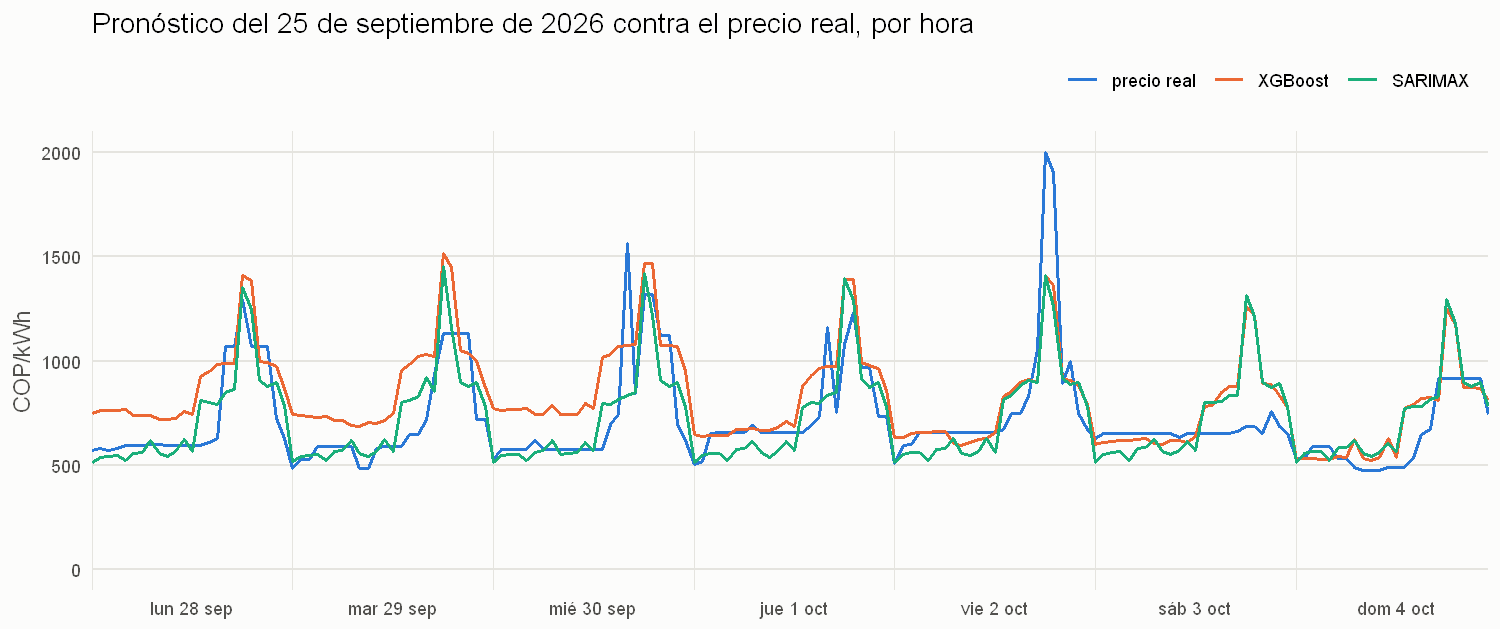

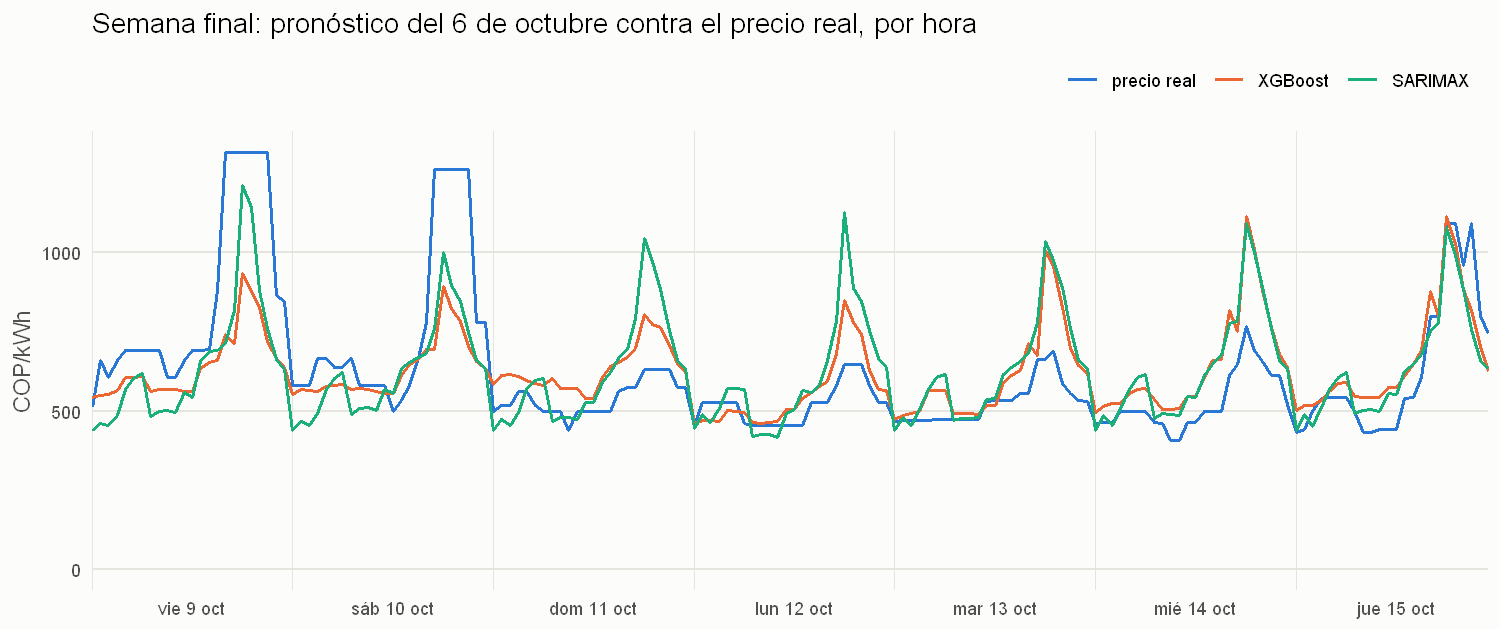

In [12]:
dias_es <- c("dom", "lun", "mar", "mié", "jue", "vie", "sáb")
meses_es <- c(`9` = "sep", `10` = "oct")

grafica_semana <- function(d, titulo, ruta) {
  d[, serie := factor(serie, levels = c("precio real", "XGBoost", "SARIMAX"))]
  dias <- seq(min(as.Date(d$momento)), max(as.Date(d$momento)), by = "day")
  corte <- as.POSIXct(paste(dias, "00:00:00"), tz = "UTC")
  etiquetas <- paste(dias_es[as.POSIXlt(dias)$wday + 1], as.POSIXlt(dias)$mday, meses_es[as.character(as.POSIXlt(dias)$mon + 1)])
  p <- ggplot(d, aes(momento, valor, color = serie)) +
    geom_vline(xintercept = corte, color = REJILLA, linewidth = .4) +
    geom_line(linewidth = .7) +
    scale_color_manual(values = c("precio real" = AZUL, XGBoost = NARANJA, SARIMAX = AGUA), name = NULL) +
    scale_x_datetime(breaks = corte + 12 * 3600, labels = etiquetas, expand = c(0, 0)) +
    scale_y_continuous(limits = c(0, NA)) +
    labs(title = titulo, x = NULL, y = "COP/kWh") +
    theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = FONDO, color = NA), panel.background = element_rect(fill = FONDO, color = NA),
          panel.grid.major.x = element_blank(), panel.grid.minor = element_blank(), panel.grid.major.y = element_line(color = REJILLA),
          axis.text = element_text(color = TEXTO_2), axis.title = element_text(color = TEXTO_2), legend.position = "top", legend.justification = "right")
  ggsave(ruta, p, width = 10, height = 4.2, dpi = 150, bg = FONDO)
  print(p)
}

largo <- function(d) melt(d, id.vars = "momento", variable.name = "serie", value.name = "valor")

if (CORRER_TEST) {
  g <- m[fecha == as.Date("2026-09-25")]
  g[, momento := as.POSIXct(fecha + h, tz = "UTC") + (hora - 1) * 3600]
  setorder(g, momento)
  grafica_semana(largo(g[, .(momento, `precio real` = exp(lp_t + y), XGBoost = exp(lp_t + y_hat_x), SARIMAX = exp(lp_t + y_hat))]),
                 "Pronóstico del 25 de septiembre de 2026 contra el precio real, por hora",
                 file.path(SALIDA, "semana_comparacion.png"))
}
if (CORRER_FINAL) {
  sem[, momento := as.POSIXct(fecha_objetivo, tz = "UTC") + (hora - 1) * 3600]
  setorder(sem, momento)
  grafica_semana(largo(sem[, .(momento, `precio real` = precio_real, XGBoost = precio_xgb, SARIMAX = precio_sar)]),
                 "Semana final: pronóstico del 6 de octubre contra el precio real, por hora",
                 file.path(SALIDA, "semana_final.png"))
}